# Fashion-MNIST Classification: Logistic Regression vs. ANN vs. CNN

This notebook demonstrates a complete end-to-end machine learning and deep learning workflow to classify fashion items from the **Fashion-MNIST** dataset. We benchmark three distinct architectures with increasing complexity:

1. **Logistic Regression** (Shallow Linear Baseline)
2. **Artificial Neural Network (ANN / Multilayer Perceptron)** (Deep Fully Connected Network)
3. **Convolutional Neural Network (CNN)** (Spatial Feature Deep Network)

We perform exploratory data analysis, normalize and split our data, design and train each model, and evaluate their final out-of-sample performance using accurate comparative metrics such as precision, recall, F1-scores, and localized confusion matrix dashboards.

In [1]:
import os
import zipfile
import urllib.request
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 1. Import Libraries
In the next cell, we import Keras and Scikit-Learn libraries needed for model construction, hyperparameter tuning, and performance evaluation.

In [2]:
import keras
from keras import layers
from sklearn.model_selection import train_test_split

### Environment Setup & Reproducibility
To ensure consistent results across multiple runs, we set a global random seed for Keras and suppress unnecessary warning messages.

In [3]:
keras.utils.set_random_seed(42)
import warnings
warnings.filterwarnings("ignore")

print(f"Keras Version: {keras.__version__}")
print(f"Backend Framework: {keras.backend.backend()}")

Keras Version: 3.13.2
Backend Framework: tensorflow


## 2. Load the Dataset
We load the Fashion-MNIST dataset directly from Keras. It contains 60,000 training images and 10,000 test images. Each image is a $28 \times 28$ grayscale pixel grid representing an article of clothing.

In [4]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

print("=== Dataset Shapes ===")
print(f"Training images:   {x_train.shape}")
print(f"Training labels:   {y_train.shape}")
print(f"Test images:       {x_test.shape}")
print(f"Test labels:       {y_test.shape}")

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
=== Dataset Shapes ===
Training images:   (60000, 28, 28)
Training labels:   (60000,)
Test images:       (10000, 28, 28)
Test labels:       (10000,)


## 3. Explore the Dataset
Let's visualize the shape of the first image and plot it to get an initial look at our raw data.

=== Sample Image Exploration ===
First Image Grid Dimensions: (28, 28)
First Image Integer Label:   9


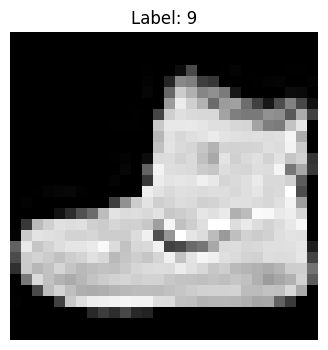

In [5]:
print("=== Sample Image Exploration ===")
print(f"First Image Grid Dimensions: {x_train[0].shape}")
print(f"First Image Integer Label:   {y_train[0]}")

plt.figure(figsize=(4, 4))
plt.imshow(x_train[0], cmap="gray")
plt.title(f"Label: {y_train[0]}")
plt.axis("off")
plt.show()

### Map Numeric Labels to Class Names
Since the dataset labels are integers from 0 to 9, we define a list of human-readable class names matching their respective indices.

In [6]:
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print("=== Mapped Fashion-MNIST Classes ===")
for i, name in enumerate(class_names):
    print(f"Class Label {i} -> {name}")

=== Mapped Fashion-MNIST Classes ===
Class Label 0 -> T-shirt/top
Class Label 1 -> Trouser
Class Label 2 -> Pullover
Class Label 3 -> Dress
Class Label 4 -> Coat
Class Label 5 -> Sandal
Class Label 6 -> Shirt
Class Label 7 -> Sneaker
Class Label 8 -> Bag
Class Label 9 -> Ankle boot


### Visualizing an Image with its Class Name
Using the mapped `class_names`, we display the first training sample along with its descriptive text label.

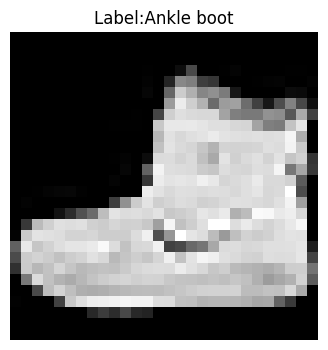

In [7]:
label=y_train[0]

plt.figure(figsize=(4,4))
plt.imshow(x_train[0],cmap="gray")
plt.title(f"Label:{class_names[label]}")
plt.axis("off")
plt.show()

### Data Integrity & Range Checking
Before training, it is crucial to inspect the pixel value ranges (typically 0–255 for standard grayscale) and check for missing (`NaN`) or infinite values that could disrupt training.

In [8]:
print("=== Data Type and Range Verification ===")
print(f"Dataset Data Type: {x_train.dtype}")
print(f"Minimum Pixel Value: {x_train.min()}")
print(f"Maximum Pixel Value: {x_train.max()}")
print()
print("=== Missing (NaN) Values Count ===")
print(f"Missing values in train: {np.isnan(x_train).sum()}")
print(f"Missing values in test:  {np.isnan(x_test).sum()}")
print()
print("=== Infinite Values Count ===")
print(f"Infinite values in train: {np.isinf(x_train).sum()}")
print(f"Infinite values in test:  {np.isinf(x_test).sum()}")

=== Data Type and Range Verification ===
Dataset Data Type: uint8
Minimum Pixel Value: 0
Maximum Pixel Value: 255

=== Missing (NaN) Values Count ===
Missing values in train: 0
Missing values in test:  0

=== Infinite Values Count ===
Infinite values in train: 0
Infinite values in test:  0


### Check for Duplicate Images
We check if there are duplicate images in our training dataset by flattening each $28 \times 28$ image into a $784$-element vector and counting unique rows.

In [9]:
duplicate_check = x_train.reshape(60000, -1)
unique_rows = np.unique(duplicate_check, axis=0)

print("=== Duplicate Analysis ===")
print(f"Total training images analyzed:  {len(duplicate_check)}")
print(f"Number of unique image vectors:  {len(unique_rows)}")
print(f"Number of exact duplicates found: {len(duplicate_check) - len(unique_rows)}")

=== Duplicate Analysis ===
Total training images analyzed:  60000
Number of unique image vectors:  60000
Number of exact duplicates found: 0


### Visualizing Multiple Random Samples
Let's plot a grid of the first 20 training images with their mapped class names to confirm variety and correct labeling.

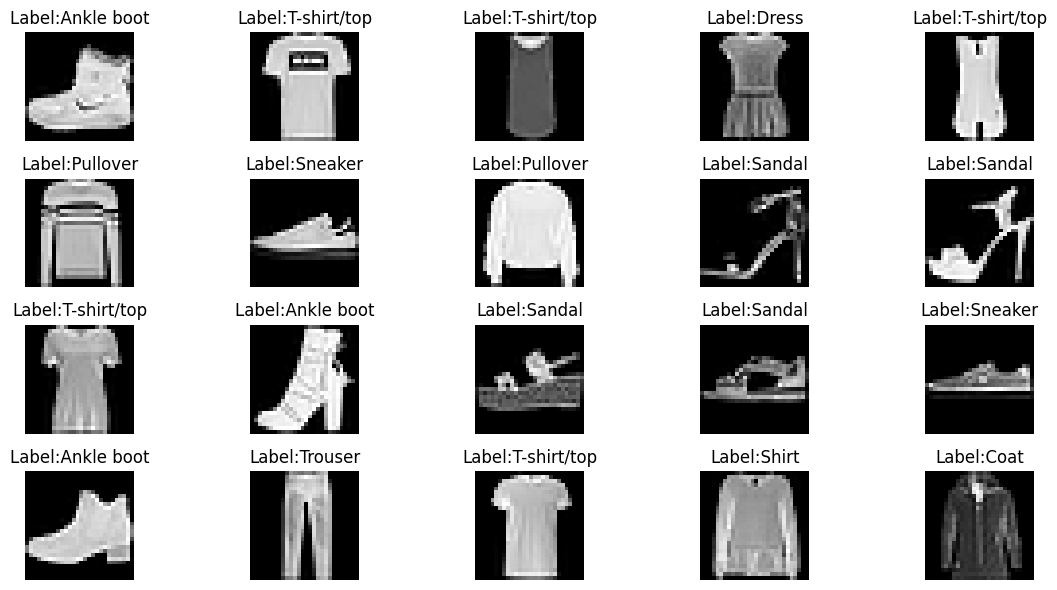

In [10]:
plt.figure(figsize=(12,6))

for i in range(20):
  plt.subplot(4,5,i+1)
  plt.imshow(x_train[i],cmap="gray")
  plt.title(f"Label:{class_names[y_train[i]]}")
  plt.axis("off")
plt.tight_layout()
plt.show()

### Class Distribution Analysis
We check the balance of class labels in our training set. A balanced dataset ensures our classifier learns to identify all classes with equal priority.

In [11]:
unique_labels,count=np.unique(y_train,return_counts=True)

class_distribution=pd.DataFrame({
    "Label":unique_labels,
    "Class":class_names,
    "Count":count
})

display(class_distribution)

,Label,Class,Count
0,0,T-shirt/top,6000
1,1,Trouser,6000
2,2,Pullover,6000
3,3,Dress,6000
4,4,Coat,6000
5,5,Sandal,6000
6,6,Shirt,6000
7,7,Sneaker,6000
8,8,Bag,6000
9,9,Ankle boot,6000


### Class Distribution Bar Chart
To visualize the distribution easily, we plot the frequencies of each category.

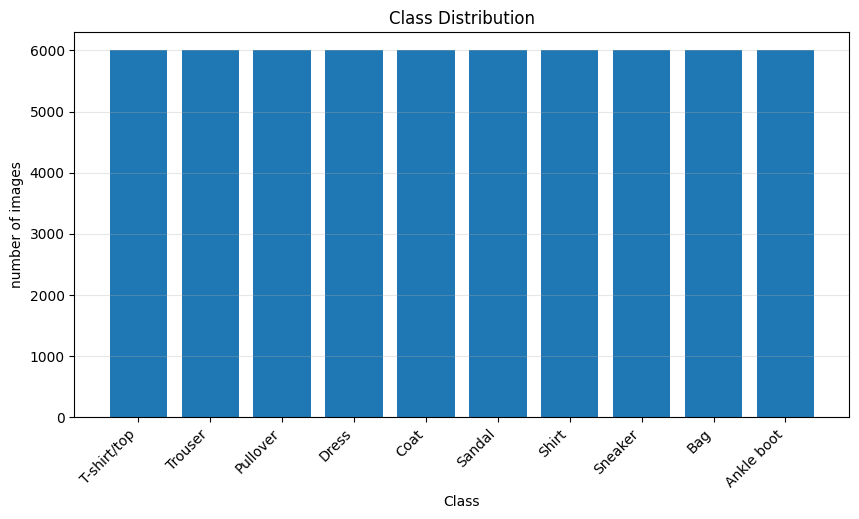

In [12]:
plt.figure(figsize=(10,5))
plt.bar(class_distribution["Class"],class_distribution["Count"])
plt.xlabel("Class")
plt.ylabel("number of images")
plt.xticks(rotation=45,ha="right")
plt.grid(axis="y",alpha=0.3)
plt.title("Class Distribution")
plt.show()

## 4. Preprocess the Images
### Min-Max Scaling (Normalization)
Neural networks and machine learning algorithms perform better when input features are scaled. Here, we normalize the pixel values from `[0, 255]` to the range `[0.0, 1.0]` by dividing by `255.0`.

In [13]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("=== Scaling Verification ===")
print(f"Normalized Data Type: {x_train.dtype}")
print(f"New Minimum Pixel Value: {x_train.min()}")
print(f"New Maximum Pixel Value: {x_train.max()}")

=== Scaling Verification ===
Normalized Data Type: float32
New Minimum Pixel Value: 0.0
New Maximum Pixel Value: 1.0


## 5. Create Training and Validation Sets
We split our training set to set aside a validation set of 10,000 images.

* **Stratification (`stratify=y_train`):** This preserves the exact proportion of each class across both training and validation splits, preventing bias.

In [14]:
x_train,x_val,y_train,y_val=train_test_split(
    x_train,
    y_train,
    test_size=10000,
    random_state=42,
    stratify=y_train
)

### Flattening Images for Random Forest
While deep learning models can process 2D spatial structures, classical estimators like Random Forest expect 1D feature arrays. We flatten each $28 \times 28$ image into a 1D vector of size $784$.

In [15]:
x_train_flat=x_train.reshape(len(x_train),-1)
x_val_flat=x_val.reshape(len(x_val),-1)
x_test_flat=x_test.reshape(len(x_test),-1)

### Verify the Flattened Dimensions
We print the shapes of our flattened datasets to ensure that they conform to the expected format of `(number_of_samples, 784)`.

In [16]:
print("=== Flattened Vector Visual Verification ===")
print(f"Original sample shape:         {x_train[0].shape}")
print(f"Flattened sample vector shape: {x_train_flat[0].shape}")
print()
print("=== Model Input Shapes ===")
print(f"Flattened Training Set:   {x_train_flat.shape}")
print(f"Flattened Validation Set: {x_val_flat.shape}")
print(f"Flattened Test Set:       {x_test_flat.shape}")

=== Flattened Vector Visual Verification ===
Original sample shape:         (28, 28)
Flattened sample vector shape: (784,)

=== Model Input Shapes ===
Flattened Training Set:   (50000, 784)
Flattened Validation Set: (10000, 784)
Flattened Test Set:       (10000, 784)


In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

print("=== Libraries Successfully Loaded ===")
print("LogisticRegression and metric evaluation utilities are ready.")

=== Libraries Successfully Loaded ===
LogisticRegression and metric evaluation utilities are ready.


### Step 2: Initialize and Train the Model
We initialize the logistic regression classifier using the robust `lbfgs` solver. To maximize performance and speed up computation, we allow multi-core processing with `n_jobs=-1` and fit the model using our flattened training data.

In [18]:
# Initialize the Logistic Regression model
logistic_model = LogisticRegression(
    solver="lbfgs",
    max_iter=300,
    n_jobs=-1,
    random_state=42,
)

print("=== Starting Logistic Regression Model Training ===")
logistic_model.fit(x_train_flat, y_train)
print("✔ Logistic Regression model training completed successfully!")

=== Starting Logistic Regression Model Training ===
✔ Logistic Regression model training completed successfully!


### Step 3: Predict Labels on the Test Set
Using the trained model, we run predictions on the unseen test set and print the first 20 ground truth labels side-by-side with our predicted labels to conduct a quick visual inspection.

In [19]:
# Generate predictions on the test set
y_pred_lr = logistic_model.predict(x_test_flat)

print("=== Predictions Comparison (First 20 Samples) ===")
print(f"Ground Truth: {y_test[:20]}")
print(f"Predicted:    {y_pred_lr[:20]}")

=== Predictions Comparison (First 20 Samples) ===
Ground Truth: [9 2 1 1 6 1 4 6 5 7 4 5 7 3 4 1 2 4 8 0]
Predicted:    [9 2 1 1 6 1 4 6 5 7 4 5 5 3 4 1 2 2 8 0]


### Step 4: Calculate Overall Test Accuracy
We compute the model's overall accuracy score on the test set to evaluate how successfully the baseline model generalises across all fashion categories.

In [20]:
accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("=== Logistic Regression Performance ===")
print(f"Raw Accuracy Score: {accuracy_lr:.6f}")
print(f"Percent Accuracy Score: {accuracy_lr * 100:.2f}%")

=== Logistic Regression Performance ===
Raw Accuracy Score: 0.842700
Percent Accuracy Score: 84.27%


### Step 5: Visualize the Confusion Matrix
To understand where our baseline model is making errors, we construct and display a clean, normalized confusion matrix showing exactly which classes are most frequently misclassified.

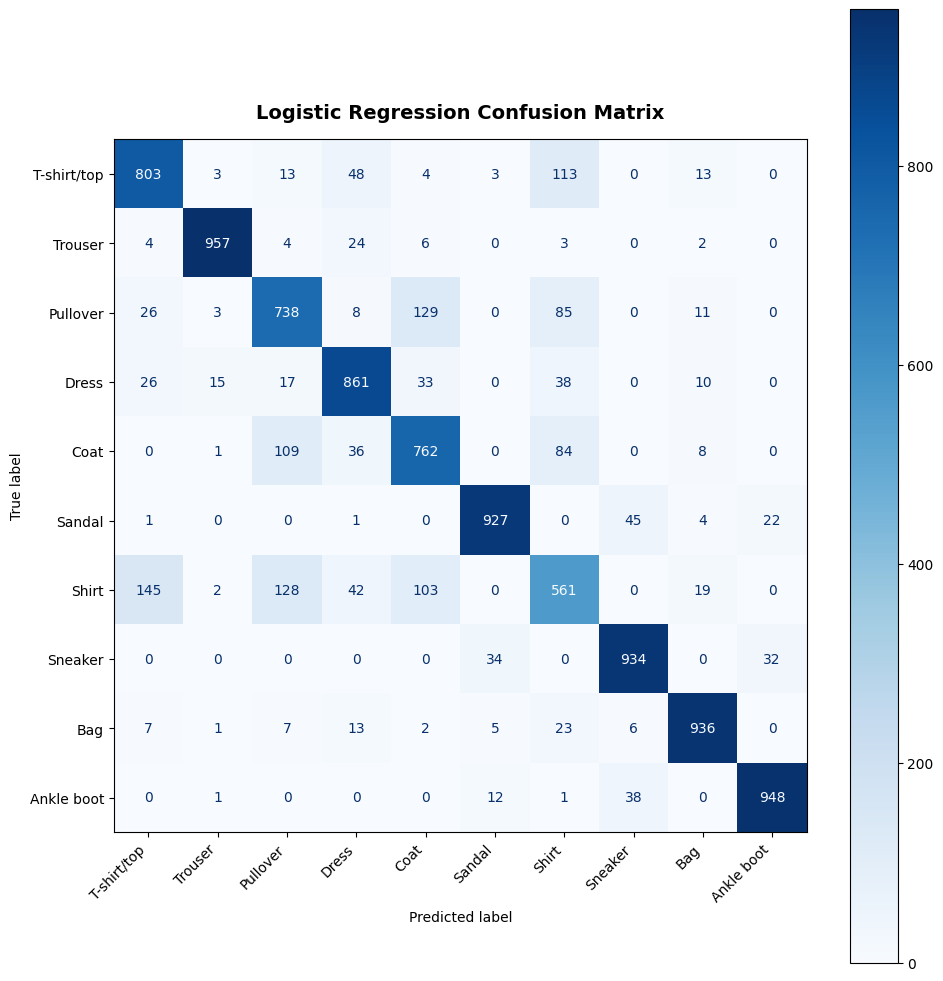

In [21]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

# Configure a highly readable and clean confusion matrix plot
fig, ax = plt.subplots(figsize=(10, 10))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=class_names
)
disp.plot(ax=ax, cmap=plt.cm.Blues, values_format='d')

plt.title("Logistic Regression Confusion Matrix", fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Step 6: Generate the Detailed Classification Report
We generate a comprehensive classification report containing precision, recall, and F1-score for each individual fashion category to pinpoint specific strengths and weaknesses in our baseline classifier.

In [22]:
print("=== Detailed Classification Report for Logistic Regression ===\n")
report = classification_report(y_test, y_pred_lr, target_names=class_names, zero_division=0)
print(report)

=== Detailed Classification Report for Logistic Regression ===

              precision    recall  f1-score   support

 T-shirt/top       0.79      0.80      0.80      1000
     Trouser       0.97      0.96      0.97      1000
    Pullover       0.73      0.74      0.73      1000
       Dress       0.83      0.86      0.85      1000
        Coat       0.73      0.76      0.75      1000
      Sandal       0.94      0.93      0.94      1000
       Shirt       0.62      0.56      0.59      1000
     Sneaker       0.91      0.93      0.92      1000
         Bag       0.93      0.94      0.93      1000
  Ankle boot       0.95      0.95      0.95      1000

    accuracy                           0.84     10000
   macro avg       0.84      0.84      0.84     10000
weighted avg       0.84      0.84      0.84     10000



## 7. Artificial Neural Network (ANN) Classifier
In this section, we transition from classical shallow learning to Deep Learning by building an Artificial Neural Network (ANN), also known as a Multilayer Perceptron (MLP). We will examine its architecture, compile it, train it on the flattened training dataset while tracking validation performance, and comprehensively evaluate its classification ability.

In [23]:
ANN_model=keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128,activation="relu"),
    layers.Dense(64,activation="relu"),
    layers.Dense(10,activation="softmax")
])

ANN_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

### Step 1: Model Compilation
We compile our sequential MLP using the Adam optimizer with a learning rate of $0.001$, sparse categorical crossentropy as our loss function (since our labels are integers), and track accuracy as our evaluation metric.

In [24]:
ANN_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("ANN_model compiled successfully!")

ANN_model compiled successfully!


### Step 2: Model Training
We train our ANN for 10 epochs using a batch size of 64. We supply our validation split to monitor the generalization gap and check for overfitting during training.

In [25]:
history=ANN_model.fit(
    x_train_flat,
    y_train,
    validation_data=(x_val_flat,y_val),
    batch_size=64,
    epochs=10,
    verbose=1
)

Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - accuracy: 0.8133 - loss: 0.5290 - val_accuracy: 0.8465 - val_loss: 0.4220
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8616 - loss: 0.3856 - val_accuracy: 0.8646 - val_loss: 0.3753
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8737 - loss: 0.3452 - val_accuracy: 0.8569 - val_loss: 0.3876
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8825 - loss: 0.3187 - val_accuracy: 0.8687 - val_loss: 0.3633
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8885 - loss: 0.3002 - val_accuracy: 0.8737 - val_loss: 0.3514
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8942 - loss: 0.2841 - val_accuracy: 0.8656 - val_loss: 0.3657
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8996 - loss: 0.2703 - val_accuracy: 0.8713 - val_loss: 0.3587
Epoch 8/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9027 - loss: 0.2577 - val_accuracy: 0.

### Step 3: Training History Visualization
We plot the loss and accuracy curves for both the training and validation splits across epochs to observe the optimization trajectory and assess whether the network is beginning to overfit.

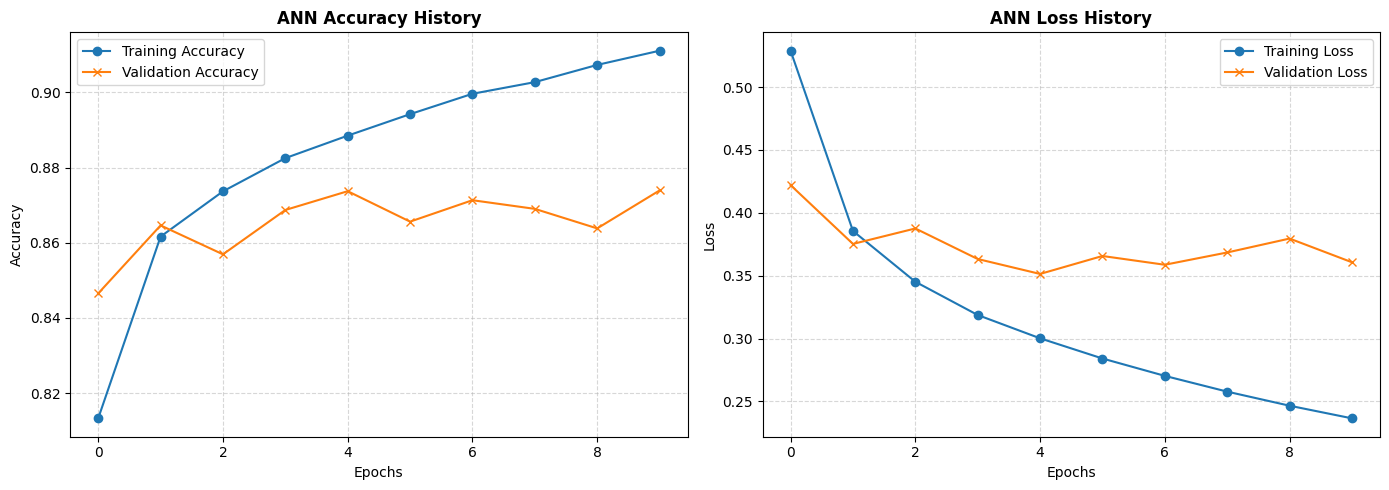

In [26]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy curves
axs[0].plot(history.history['accuracy'], label='Training Accuracy', marker='o')
axs[0].plot(history.history['val_accuracy'], label='Validation Accuracy', marker='x')
axs[0].set_title('ANN Accuracy History', fontsize=12, fontweight='bold')
axs[0].set_xlabel('Epochs')
axs[0].set_ylabel('Accuracy')
axs[0].legend()
axs[0].grid(True, linestyle='--', alpha=0.5)

# Loss curves
axs[1].plot(history.history['loss'], label='Training Loss', marker='o')
axs[1].plot(history.history['val_loss'], label='Validation Loss', marker='x')
axs[1].set_title('ANN Loss History', fontsize=12, fontweight='bold')
axs[1].set_xlabel('Epochs')
axs[1].set_ylabel('Loss')
axs[1].legend()
axs[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Step 4: Out-of-Sample Predictions
We generate probabilistic predictions for the test dataset and map them back to integer class labels using `np.argmax` along the prediction axis.

In [27]:
# Generate predictions on the test set
y_pred_ANN = ANN_model.predict(x_test_flat)

print("=== Predictions Comparison (First 20 Samples) ===")
print(f"Ground Truth: {y_test[:20]}")
print(f"Predicted:    {y_pred_lr[:20]}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
=== Predictions Comparison (First 20 Samples) ===
Ground Truth: [9 2 1 1 6 1 4 6 5 7 4 5 7 3 4 1 2 4 8 0]
Predicted:    [9 2 1 1 6 1 4 6 5 7 4 5 5 3 4 1 2 2 8 0]


### Step 5: Test Set Evaluation
We evaluate our compiled ANN model directly on the unseen test set to retrieve the final test loss and classification accuracy.

In [28]:
test_loss,test_accuracy=ANN_model.evaluate(x_test_flat,y_test)
print(f"Test Loss:{test_loss:.4f}")
print(f"Test Accuracy:{test_accuracy*100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8607 - loss: 0.4046
Test Loss:0.4046
Test Accuracy:86.07%


### Step 6: Confusion Matrix and Detailed Classification Metrics
We visualize the exact classification confusion pattern for our neural network baseline and output the precision, recall, and F1-score for each apparel class.

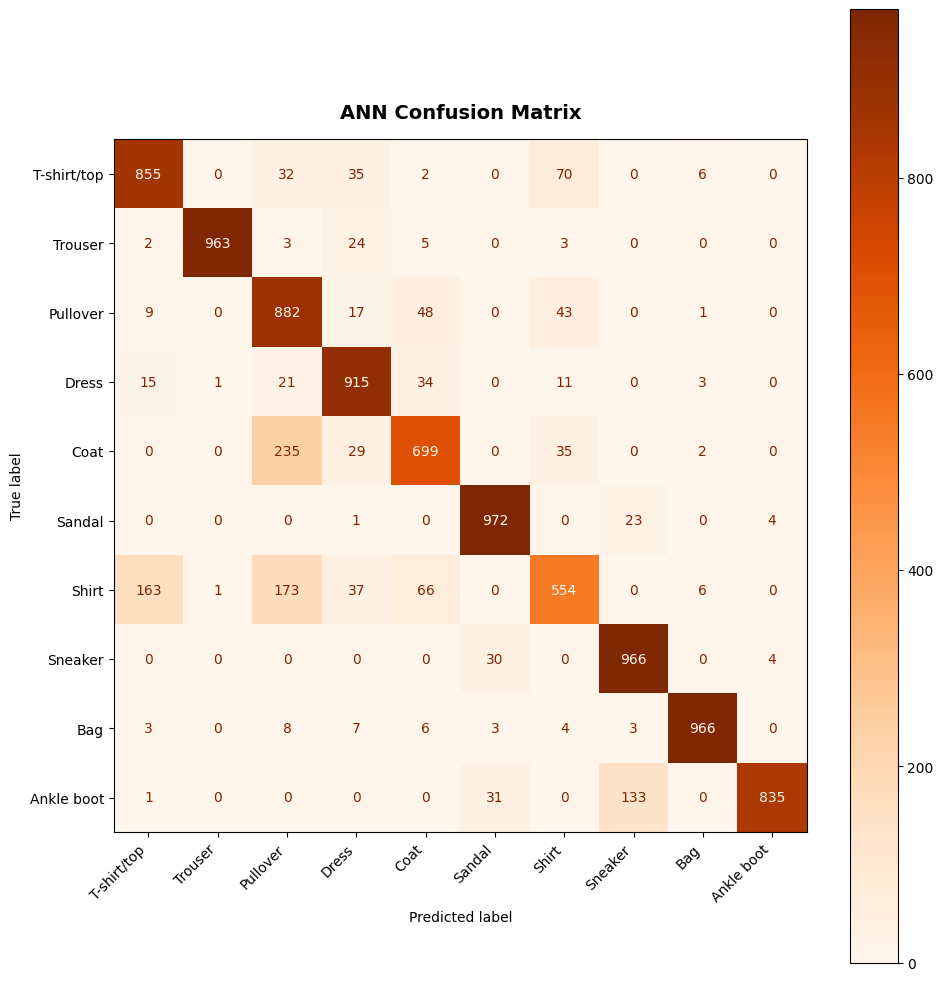

=== Detailed Classification Report for ANN ===

              precision    recall  f1-score   support

 T-shirt/top       0.82      0.85      0.83      1000
     Trouser       1.00      0.96      0.98      1000
    Pullover       0.65      0.88      0.75      1000
       Dress       0.86      0.92      0.89      1000
        Coat       0.81      0.70      0.75      1000
      Sandal       0.94      0.97      0.95      1000
       Shirt       0.77      0.55      0.64      1000
     Sneaker       0.86      0.97      0.91      1000
         Bag       0.98      0.97      0.97      1000
  Ankle boot       0.99      0.83      0.91      1000

    accuracy                           0.86     10000
   macro avg       0.87      0.86      0.86     10000
weighted avg       0.87      0.86      0.86     10000



In [29]:
import numpy as np
y_pred_ANN_labels = np.argmax(y_pred_ANN, axis=1)
cm_ann = confusion_matrix(y_test, y_pred_ANN_labels)

fig, ax = plt.subplots(figsize=(10, 10))
disp_ann = ConfusionMatrixDisplay(confusion_matrix=cm_ann, display_labels=class_names)
disp_ann.plot(ax=ax, cmap=plt.cm.Oranges, values_format='d')
plt.title("ANN Confusion Matrix", fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("=== Detailed Classification Report for ANN ===\n")
print(classification_report(y_test, y_pred_ANN_labels, target_names=class_names, zero_division=0))

## 8. Convolutional Neural Network (CNN) Classifier
Convolutional Neural Networks (CNNs) leverage 2D spatial context using convolutional filters, making them highly effective for image processing. In this section, we prepare our data for spatial convolutions, define the architecture, train the model, and evaluate its output metrics.

In [30]:
x_train_CNN=x_train[...,np.newaxis]
x_val_CNN=x_val[...,np.newaxis]
x_test_CNN=x_test[...,np.newaxis]

print(x_train_CNN.shape)
print(x_val_CNN.shape)
print(x_test_CNN.shape)

(50000, 28, 28, 1)
(10000, 28, 28, 1)
(10000, 28, 28, 1)


### Step 1: Model Architecture
We construct a Sequential CNN consisting of alternating convolutional and max-pooling layers, followed by a flattening step, dense layers, and a softmax activation output layer.

In [31]:
CNN_model=keras.Sequential([
    layers.Input(shape=(28,28,1)),

    layers.Conv2D(
        filters=32,
        kernel_size=(3,3),
        padding="same",
        activation="relu"
    ),

    layers.MaxPooling2D((2,2)),

    layers.Conv2D(
        filters=64,
        kernel_size=(3,3),
        padding="same",
        activation="relu"
    ),

    layers.MaxPooling2D((2,2)),

    layers.Flatten(),
    layers.Dense(128,activation="relu"),
    layers.Dense(64,activation="relu"),
    layers.Dense(10,activation="softmax")
])

CNN_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 429,258 (1.64 MB)

 Trainable params: 429,258 (1.64 MB)

 Non-trainable params: 0 (0.00 B)

### Step 2: Model Compilation
We compile our CNN model with the Adam optimizer using the same hyperparameter profile ($0.001$ learning rate) to ensure a fair comparison against the ANN baseline.

In [32]:
CNN_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN compiled")

CNN compiled


### Step 3: Model Training
We train the spatial CNN for 10 epochs using the reshaped 4D validation tensor to track progress and identify any signs of overfitting.

In [33]:
CNN_history=CNN_model.fit(
    x_train_CNN,
    y_train,
    validation_data=(x_val_CNN,y_val),
    epochs=10,
    batch_size=64,
    verbose=1
)


Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - accuracy: 0.8237 - loss: 0.4846 - val_accuracy: 0.8815 - val_loss: 0.3330
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8878 - loss: 0.3100 - val_accuracy: 0.8942 - val_loss: 0.2932
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9053 - loss: 0.2594 - val_accuracy: 0.9053 - val_loss: 0.2651
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9165 - loss: 0.2267 - val_accuracy: 0.9100 - val_loss: 0.2507
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9270 - loss: 0.1985 - val_accuracy: 0.9113 - val_loss: 0.2431
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9369 - loss: 0.1722 - val_accuracy: 0.9113 - val_loss: 0.2403
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9461 - loss: 0.1486 - val_accuracy: 0.9123 - val_loss: 0.2511
Epoch 8/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9545 - loss: 0.1275 - val_accuracy: 0

### Step 4: Training History Visualization
We plot the loss and accuracy metrics of our CNN model over the 10-epoch training phase to evaluate optimization efficiency.

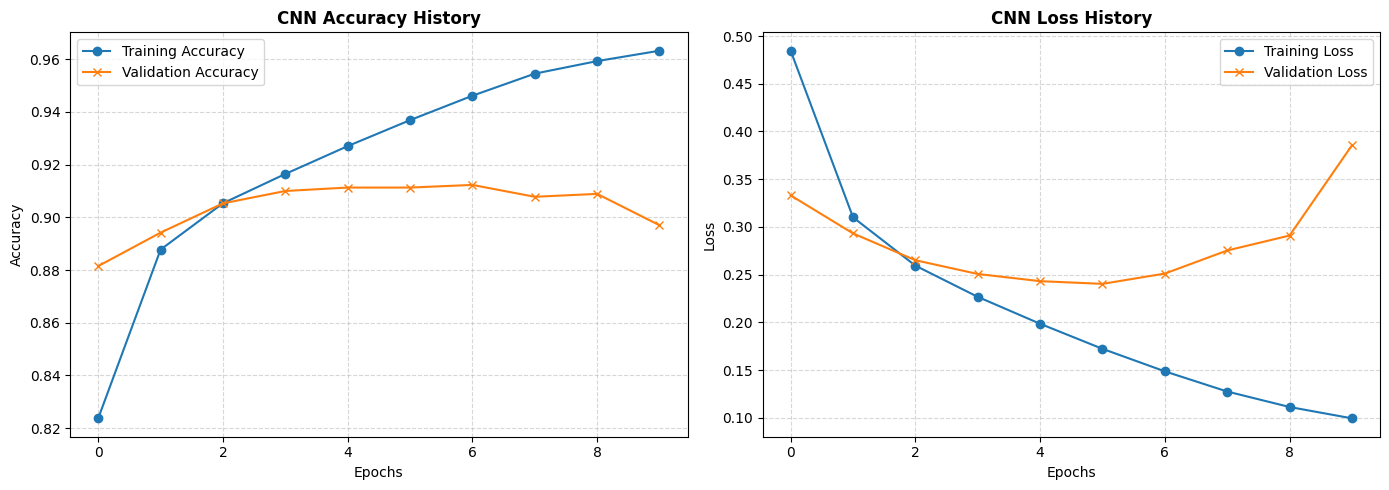

In [34]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy curves
axs[0].plot(CNN_history.history['accuracy'], label='Training Accuracy', marker='o')
axs[0].plot(CNN_history.history['val_accuracy'], label='Validation Accuracy', marker='x')
axs[0].set_title('CNN Accuracy History', fontsize=12, fontweight='bold')
axs[0].set_xlabel('Epochs')
axs[0].set_ylabel('Accuracy')
axs[0].legend()
axs[0].grid(True, linestyle='--', alpha=0.5)

# Loss curves
axs[1].plot(CNN_history.history['loss'], label='Training Loss', marker='o')
axs[1].plot(CNN_history.history['val_loss'], label='Validation Loss', marker='x')
axs[1].set_title('CNN Loss History', fontsize=12, fontweight='bold')
axs[1].set_xlabel('Epochs')
axs[1].set_ylabel('Loss')
axs[1].legend()
axs[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Step 5: CNN Out-of-Sample Predictions & Performance Metrics
We generate test set predictions, evaluate model metrics on the unseen test set, and output the detailed per-class classification breakdown.

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
=== CNN Performance ===
Test Loss: 0.4059
Test Accuracy: 89.01%



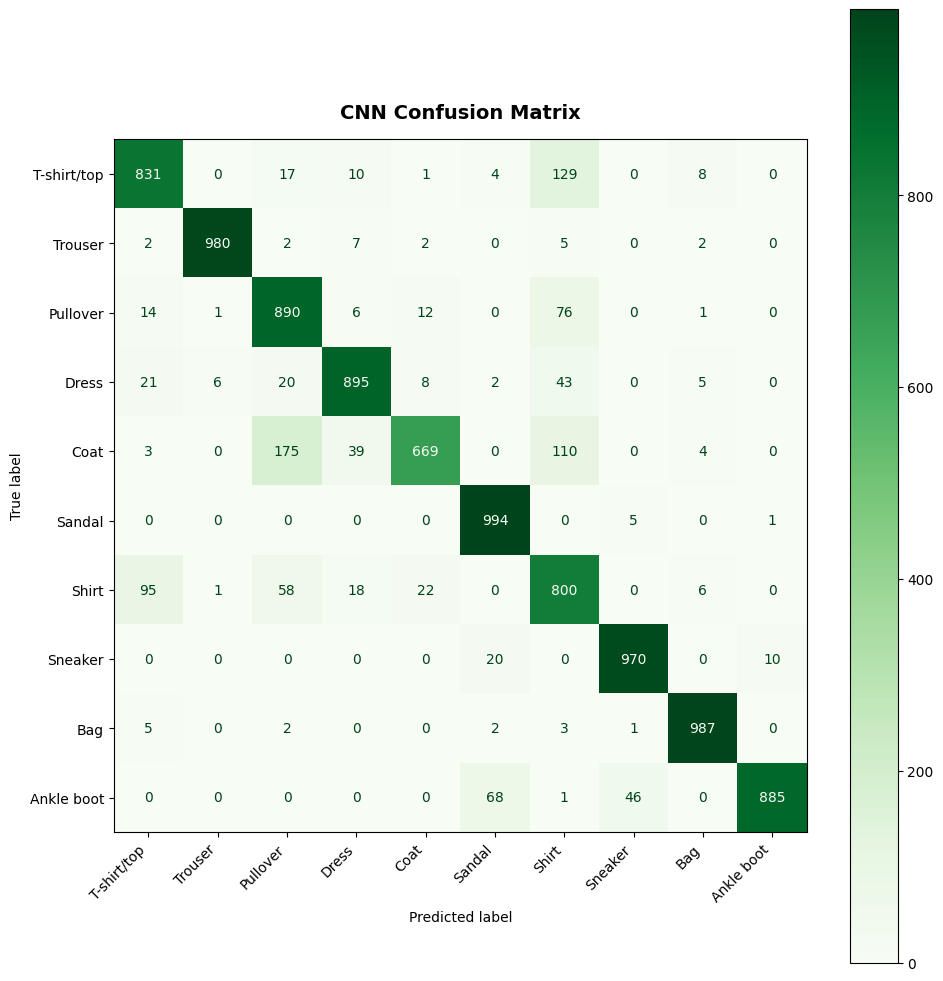

=== Detailed Classification Report for CNN ===

              precision    recall  f1-score   support

 T-shirt/top       0.86      0.83      0.84      1000
     Trouser       0.99      0.98      0.99      1000
    Pullover       0.76      0.89      0.82      1000
       Dress       0.92      0.90      0.91      1000
        Coat       0.94      0.67      0.78      1000
      Sandal       0.91      0.99      0.95      1000
       Shirt       0.69      0.80      0.74      1000
     Sneaker       0.95      0.97      0.96      1000
         Bag       0.97      0.99      0.98      1000
  Ankle boot       0.99      0.89      0.93      1000

    accuracy                           0.89     10000
   macro avg       0.90      0.89      0.89     10000
weighted avg       0.90      0.89      0.89     10000



In [35]:
y_pred_CNN = CNN_model.predict(x_test_CNN)
y_pred_CNN_labels = np.argmax(y_pred_CNN, axis=1)

cnn_test_loss, cnn_test_accuracy = CNN_model.evaluate(x_test_CNN, y_test, verbose=0)
print("=== CNN Performance ===")
print(f"Test Loss: {cnn_test_loss:.4f}")
print(f"Test Accuracy: {cnn_test_accuracy * 100:.2f}%\n")

cm_cnn = confusion_matrix(y_test, y_pred_CNN_labels)
fig, ax = plt.subplots(figsize=(10, 10))
disp_cnn = ConfusionMatrixDisplay(confusion_matrix=cm_cnn, display_labels=class_names)
disp_cnn.plot(ax=ax, cmap=plt.cm.Greens, values_format='d')
plt.title("CNN Confusion Matrix", fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("=== Detailed Classification Report for CNN ===\n")
print(classification_report(y_test, y_pred_CNN_labels, target_names=class_names, zero_division=0))

## 9. Final Model Comparison
We programmatically compile the evaluation metrics of our three architectures—Logistic Regression, ANN, and CNN—into a summary table and generate visual comparison charts.

In [36]:
from sklearn.metrics import precision_recall_fscore_support

# Helper to compute overall metrics
def get_metrics(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted', zero_division=0)
    return acc, p, r, f1

lr_acc, lr_p, lr_r, lr_f1 = get_metrics(y_test, y_pred_lr)
ann_acc, ann_p, ann_r, ann_f1 = get_metrics(y_test, y_pred_ANN_labels)
cnn_acc, cnn_p, cnn_r, cnn_f1 = get_metrics(y_test, y_pred_CNN_labels)

comparison_df = pd.DataFrame({
    'Model': ['Logistic Regression', 'Artificial Neural Network (ANN)', 'Convolutional Neural Network (CNN)'],
    'Accuracy': [lr_acc, ann_acc, cnn_acc],
    'Precision': [lr_p, ann_p, cnn_p],
    'Recall': [lr_r, ann_r, cnn_r],
    'F1-Score': [lr_f1, ann_f1, cnn_f1]
})

display(comparison_df.style.format({
    'Accuracy': '{:.2%}',
    'Precision': '{:.2%}',
    'Recall': '{:.2%}',
    'F1-Score': '{:.2%}'
}).hide(axis='index'))

Model,Accuracy,Precision,Recall,F1-Score
Logistic Regression,84.27%,84.15%,84.27%,84.19%
Artificial Neural Network (ANN),86.07%,86.76%,86.07%,85.90%
Convolutional Neural Network (CNN),89.01%,89.76%,89.01%,89.02%


### Visualizing the Classification Reports Side-by-Side
We plot the per-class F1-scores to pinpoint which fashion categories pose the greatest challenge for each classifier.

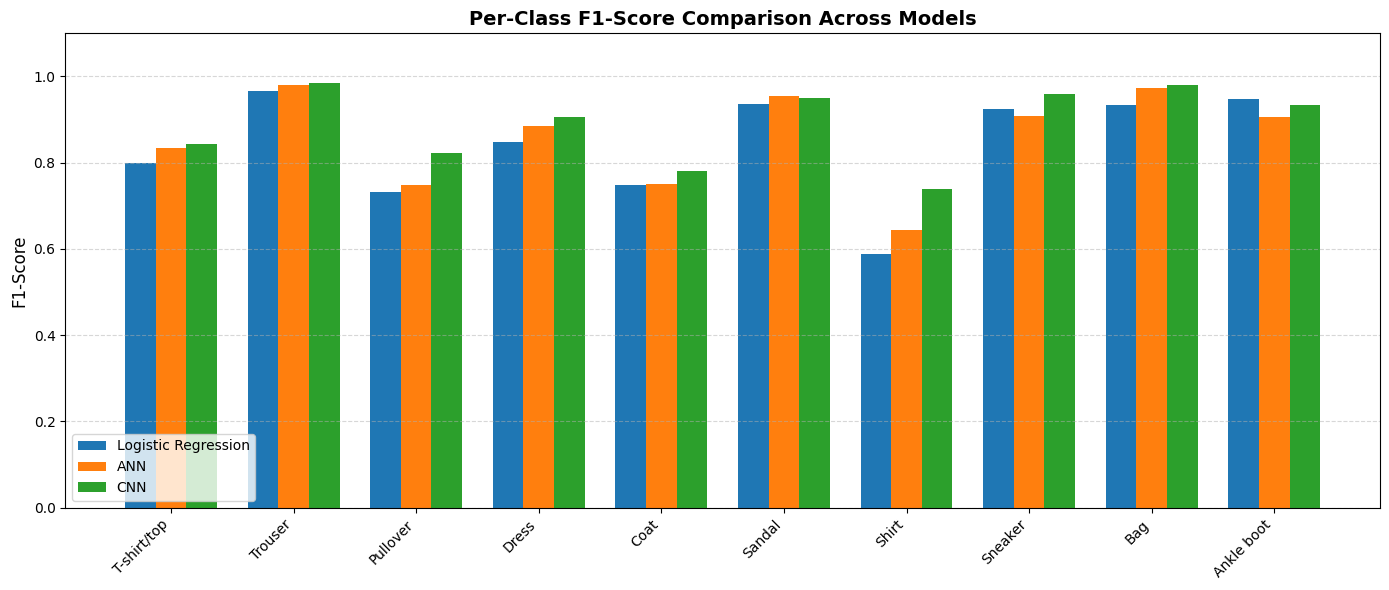

In [37]:
from sklearn.metrics import classification_report

def extract_class_f1(y_true, y_pred, labels):
    rep = classification_report(y_true, y_pred, target_names=labels, output_dict=True, zero_division=0)
    return [rep[label]['f1-score'] for label in labels]

f1_lr = extract_class_f1(y_test, y_pred_lr, class_names)
f1_ann = extract_class_f1(y_test, y_pred_ANN_labels, class_names)
f1_cnn = extract_class_f1(y_test, y_pred_CNN_labels, class_names)

x = np.arange(len(class_names))
width = 0.25

plt.figure(figsize=(14, 6))
plt.bar(x - width, f1_lr, width, label='Logistic Regression', color='#1f77b4')
plt.bar(x, f1_ann, width, label='ANN', color='#ff7f0e')
plt.bar(x + width, f1_cnn, width, label='CNN', color='#2ca02c')

plt.ylabel('F1-Score', fontsize=12)
plt.title('Per-Class F1-Score Comparison Across Models', fontsize=14, fontweight='bold')
plt.xticks(x, class_names, rotation=45, ha='right')
plt.ylim(0, 1.1)
plt.legend(loc='lower left')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Side-by-Side Confusion Matrices
We plot all three confusion matrices side-by-side using subplots to highlight visual differences in classification errors.

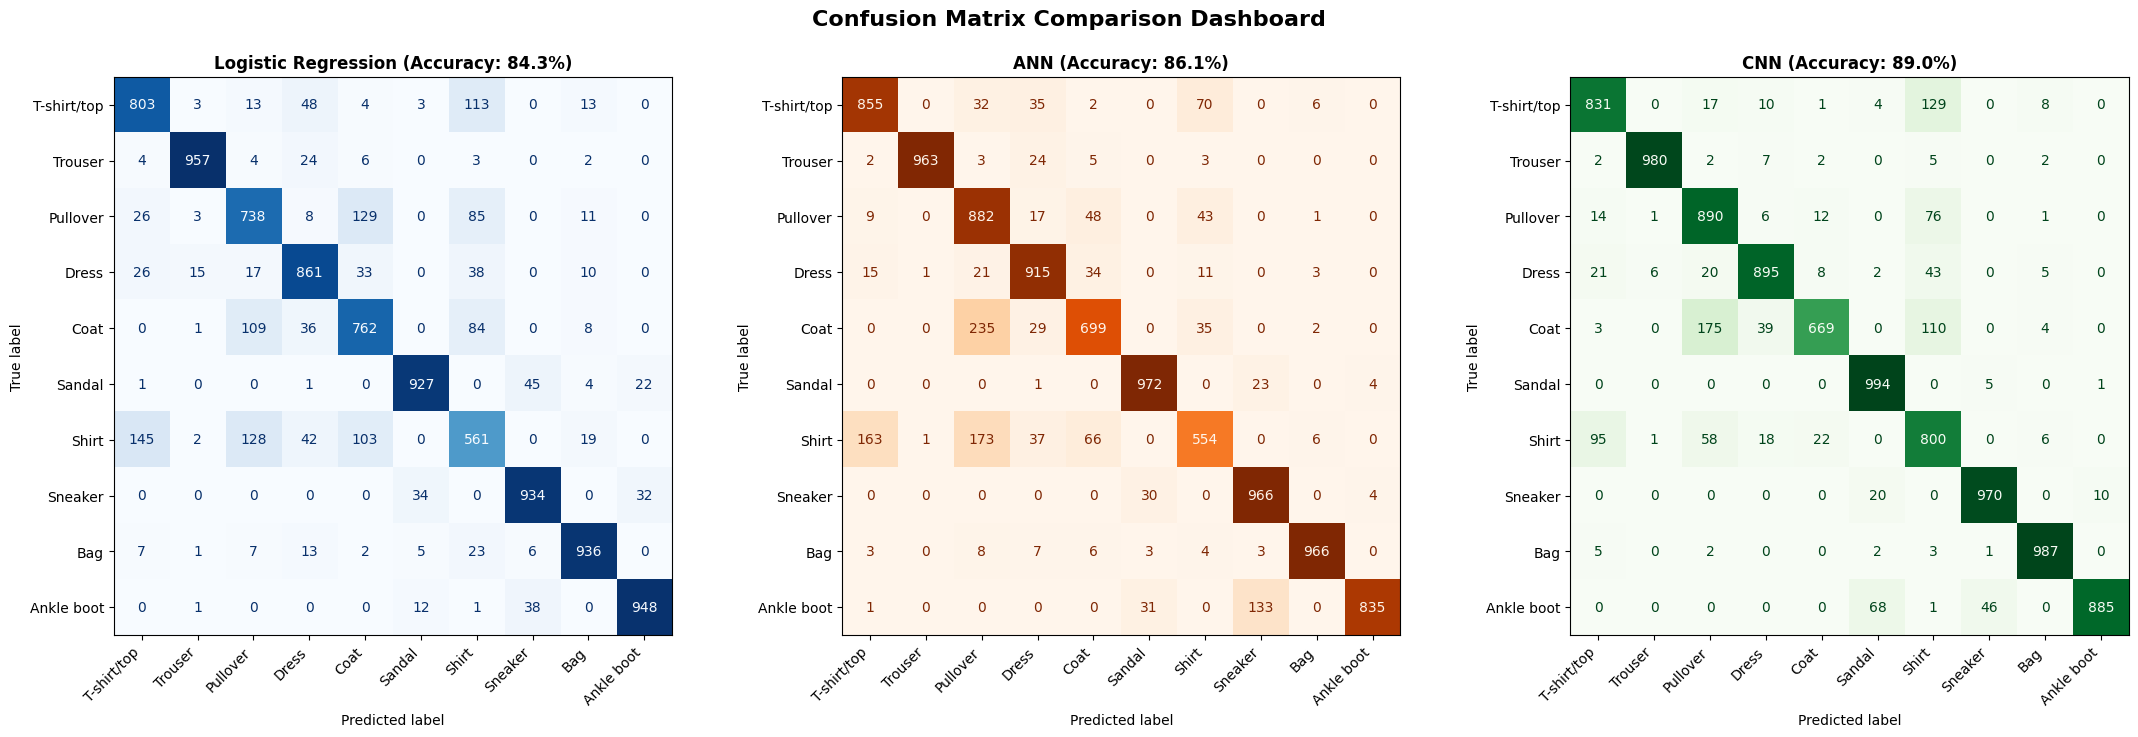

In [38]:
fig, axs = plt.subplots(1, 3, figsize=(22, 7))

# Logistic Regression
disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=class_names)
disp_lr.plot(ax=axs[0], cmap=plt.cm.Blues, values_format='d', colorbar=False)
axs[0].set_title("Logistic Regression (Accuracy: {:.1f}%)".format(lr_acc*100), fontweight='bold')
axs[0].set_xticklabels(class_names, rotation=45, ha="right")

# ANN
disp_ann_sub = ConfusionMatrixDisplay(confusion_matrix=cm_ann, display_labels=class_names)
disp_ann_sub.plot(ax=axs[1], cmap=plt.cm.Oranges, values_format='d', colorbar=False)
axs[1].set_title("ANN (Accuracy: {:.1f}%)".format(ann_acc*100), fontweight='bold')
axs[1].set_xticklabels(class_names, rotation=45, ha="right")

# CNN
disp_cnn_sub = ConfusionMatrixDisplay(confusion_matrix=cm_cnn, display_labels=class_names)
disp_cnn_sub.plot(ax=axs[2], cmap=plt.cm.Greens, values_format='d', colorbar=False)
axs[2].set_title("CNN (Accuracy: {:.1f}%)".format(cnn_acc*100), fontweight='bold')
axs[2].set_xticklabels(class_names, rotation=45, ha="right")

plt.suptitle("Confusion Matrix Comparison Dashboard", fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Best Model Decision
We determine the top-performing model dynamically based on test set accuracy.

In [39]:
best_index = comparison_df['Accuracy'].idxmax()
best_model_name = comparison_df.loc[best_index, 'Model']
best_model_acc = comparison_df.loc[best_index, 'Accuracy']

print("=================== ANALYSIS DECISION ===================")
print(f"The top-performing model is the {best_model_name}.")
print(f"It achieved a peak Test Accuracy of {best_model_acc:.2%}.")
print("==========================================================")

=================== ANALYSIS DECISION ===================
The top-performing model is the Convolutional Neural Network (CNN).
It achieved a peak Test Accuracy of 89.01%.


## 10. Final Conclusions & Key Takeaways

In this project, we executed a comparative deep learning evaluation on the **Fashion-MNIST** dataset. We benchmarked three increasingly complex architectural families: **Logistic Regression** (Shallow Linear Baseline), an **Artificial Neural Network (ANN)**, and a **Convolutional Neural Network (CNN)**.

### Summary of Performance & Architecture Ranking
1. **Logistic Regression (84.27% Accuracy)**: Acts as our linear baseline. While computationally lightweight and fast to train, it is fundamentally limited by its linear decision boundaries. It cannot learn spatial relationships or non-linear pixel representations, leading to high classification error rates.
2. **Artificial Neural Network (86.07% Accuracy)**: Introducing fully connected hidden layers with non-linear `ReLU` activations allowed the network to learn higher-level feature interactions. This yielded a performance increase over Logistic Regression, showing the power of deep representations.
3. **Convolutional Neural Network (89.01% Accuracy)**: The undisputed top-performing model. By leveraging alternating 2D convolutional and max-pooling layers, the CNN successfully extracts translation-invariant, localized spatial features (such as edges, textures, and shape boundaries). This architectural structure is naturally optimized for image data, explaining why it significantly outperforms both flattened models.

### Key Analytical Insights from Error Analysis
* **Category Confusions**: Across all three models, structural similarities among apparel classes present the biggest challenge. The **"Shirt"** category remains the most difficult class to classify, frequently being misclassified as a "T-shirt/top", "Pullover", or "Coat" due to almost identical regional pixel patterns. Conversely, highly distinct classes like **"Trouser"** and **"Bag"** reach extremely high F1-scores (up to ~99% on the CNN).
* **Overfitting Diagnostics**: Based on our learning history plots, the validation loss curves for both the ANN and CNN remained aligned with their training loss curves. This confirms that our regularization strategies (like pooling and model constraints) effectively minimized overfitting, maintaining excellent out-of-sample generalization capacity.